# 03 · Research-Domain Classification and Keywords

**Use Case 3: Research Paper Analysis and Recommendation System**  
**Owner:** Member B (classification lead)

**Goal:** Predict a paper's primary research domain (6 CS categories) and extract its keywords.

**Basic techniques (Weeks 1–6)**
- TF-IDF keyword extraction (top-weighted terms per paper and per category)
- Traditional classification: Naive Bayes and Logistic Regression on BoW vs TF-IDF features

**Advanced techniques (Weeks 7–12)**
- Fine-tune DistilBERT/SciBERT **or** zero/few-shot LLM classification
- Optional: ensemble of the best traditional model and the transformer

**Evaluation:** Accuracy, macro-F1 and a confusion matrix on the shared test split for every model. Discuss cross-listed papers (about 54% of the sample) as a source of error.

**Report section:** Classification; the comparative-analysis table across all members (~1,000 words).

## Setup

Run `01_data_loading_and_sampling.ipynb` first. Always evaluate on `test_df`.

In [1]:
from utils import load_sample, load_split

df = load_sample()
train_df, test_df = load_split(df)
print(f"all={len(df):,}  train={len(train_df):,}  test={len(test_df):,}")
train_df[["id", "primary_category", "title"]].head()

all=12,000  train=9,600  test=2,400


,id,primary_category,title
0,2404.00934,cs.CL,ChatGLM-RLHF: Practices of Aligning Large Lang...
1,2304.01712,cs.CL,Rumour Detection and Analysis on Twitter
2,2509.24120,cs.CL,EduVidQA: Generating and Evaluating Long-form ...
3,1706.03747,cs.CL,Acoustic data-driven lexicon learning based on...
4,1805.04793,cs.CL,Coarse-to-Fine Decoding for Neural Semantic Pa...


In [2]:
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
import os
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
transformers.logging.set_verbosity_error()
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.naive_bayes import MultinomialNB

import classify as clf
from extraction import clean_text
from utils import save_results, ARTIFACTS_DIR

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

CATEGORIES = clf.CATEGORIES
y_train = train_df["primary_category"]
y_test = test_df["primary_category"]

# Sizes and models for the slower advanced parts (subsets, as agreed in the team plan)
ZERO_SHOT_N = 500             # W7 zero-shot on 500 test papers
FINETUNE_TRAIN_N = 3000       # W9 DistilBERT fine-tune on 3,000 training papers, 1 epoch
LLM_N = 200                   # W9 few-shot LLM classifier on 200 test papers
ZERO_SHOT_MODEL = "sileod/deberta-v3-base-tasksource-nli"   # same model as the Week 7 practical
DISTILBERT = "distilbert-base-uncased"                      # Week 6 tokenizer and Week 9 fine-tuning model

HAS_GPU = torch.cuda.is_available()
print("GPU available:", HAS_GPU, "|", torch.cuda.get_device_name(0) if HAS_GPU else "CPU only")
results = {"models": []}      # one row per model; saved with save_results("03", ...) at the end

GPU available: True | NVIDIA GeForce RTX 4060 Laptop GPU


## TF-IDF keywords

Week 4 TF-IDF, fitted on the training papers only (after `clean_text` from Part A removes LaTeX). A domain's keywords are the terms with the highest **average** TF-IDF weight over that domain's papers; a paper's keywords are its own highest-weighted terms. Unigrams and bigrams are used so phrases like "language models" survive.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Week 4 TF-IDF is used twice: as the classifier's features and as a keyword extractor. Mean TF-IDF weight per domain gives interpretable domain vocabularies (the demo and slides use them), and a paper's top-weighted terms are its keywords. Bigrams are kept so phrases like "language models" survive; `max_df=0.5` drops words common to all CS papers.


In [3]:
keyword_vectoriser = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5,
                                     sublinear_tf=True, ngram_range=(1, 2))
# clean_text (from extraction.py) strips LaTeX such as \textbf{...} so it does not show up as a keyword
X_keywords = keyword_vectoriser.fit_transform(train_df["text"].map(clean_text))
terms = keyword_vectoriser.get_feature_names_out()

domain_keywords = {}
for category in CATEGORIES:
    rows = np.where(y_train.values == category)[0]
    mean_weights = np.asarray(X_keywords[rows].mean(axis=0)).ravel()
    best = np.argsort(mean_weights)[::-1][:10]
    domain_keywords[category] = [terms[j] for j in best]

results["domain_keywords"] = domain_keywords
pd.DataFrame(domain_keywords)

,cs.AI,cs.CL,cs.CR,cs.CV,cs.IR,cs.LG
0,agent,language,security,image,recommendation,learning
1,reasoning,models,attacks,images,user,data
2,ai,language models,privacy,3d,retrieval,model
3,agents,llms,attack,object,search,neural
4,models,model,data,model,based,models
5,model,text,based,method,systems,training
6,learning,large,secure,methods,recommender,networks
7,based,large language,paper,visual,item,based
8,language,tasks,detection,video,information,deep
9,knowledge,task,blockchain,learning,users,methods


In [4]:
# Keywords of three individual test papers
for _, row in test_df.sample(n=3, random_state=SEED).iterrows():
    weights = keyword_vectoriser.transform([clean_text(row["text"])]).toarray().ravel()
    best = np.argsort(weights)[::-1][:6]
    print(f"[{row['primary_category']}] {row['title']}")
    print("   ->", [terms[j] for j in best if weights[j] > 0], "\n")

[cs.CR] The Right to be Forgotten in Federated Learning: An Efficient Realization with Rapid Retraining
   -> ['unlearning', 'holders', 'machine unlearning', 'data holders', 'fl', 'right forgotten'] 

[cs.IR] Sequential Recommendation via Stochastic Self-Attention
   -> ['start items', 'transitivity', 'self attention', 'dot product', 'dot', 'items'] 

[cs.LG] A Generative Neural Annealer for Black-Box Combinatorial Optimization
   -> ['temperatures', 'black box', 'black', 'combinatorial', 'combinatorial optimization', 'box'] 



## BoW / TF-IDF + NB / LogReg baselines

Week 5 pipeline: Multinomial Naive Bayes on BoW counts and on TF-IDF, Logistic Regression on TF-IDF (same unigram vocabulary, so only the model or the weighting changes), plus Logistic Regression on unigrams + bigrams. Classes are balanced (1,600 train / 400 test each), so **macro-F1** is the main metric next to accuracy.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Week 5 classical models are the supervised baseline the advanced models must beat. Holding the vocabulary fixed and changing one thing at a time (BoW vs TF-IDF, NB vs LogReg) isolates what helps. Classes are balanced, so accuracy and macro-F1 agree; the train/test gap column checks for over-fitting.


In [5]:
def evaluate(y_true, y_pred, model_name, n_note=""):
    """Accuracy and macro precision/recall/F1 (adapted from evaluate_model in the Week 5 practical)."""
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=CATEGORIES, average="macro", zero_division=0)   # labels=: an "unparsed" LLM answer never becomes a 7th class
    row = {"model": model_name, "test_papers": len(y_true), "accuracy": round(accuracy, 3),
           "macro_precision": round(precision, 3), "macro_recall": round(recall, 3), "macro_f1": round(f1, 3)}
    if n_note:
        row["note"] = n_note
    return row


def plot_confusion_matrix(y_true, y_pred, model_name):
    """Week 5 heatmap."""
    cm = confusion_matrix(y_true, y_pred, labels=CATEGORIES)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATEGORIES, yticklabels=CATEGORIES)
    plt.title(f"Confusion matrix - {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    return cm

In [6]:
bow_vectoriser = CountVectorizer(stop_words="english", min_df=2)
tfidf_vectoriser = TfidfVectorizer(stop_words="english", min_df=2, sublinear_tf=True)

X_train_bow = bow_vectoriser.fit_transform(train_df["text"])
X_test_bow = bow_vectoriser.transform(test_df["text"])
X_train_tfidf = tfidf_vectoriser.fit_transform(train_df["text"])
X_test_tfidf = tfidf_vectoriser.transform(test_df["text"])
print("BoW:", X_train_bow.shape, " TF-IDF:", X_train_tfidf.shape)

BoW: (9600, 17519)  TF-IDF: (9600, 17519)


In [7]:
classical_rows = []
train_accuracy = {}

nb_bow = MultinomialNB().fit(X_train_bow, y_train)
classical_rows.append(evaluate(y_test, nb_bow.predict(X_test_bow), "Naive Bayes + BoW"))
train_accuracy["Naive Bayes + BoW"] = accuracy_score(y_train, nb_bow.predict(X_train_bow))

nb_tfidf = MultinomialNB().fit(X_train_tfidf, y_train)
classical_rows.append(evaluate(y_test, nb_tfidf.predict(X_test_tfidf), "Naive Bayes + TF-IDF"))
train_accuracy["Naive Bayes + TF-IDF"] = accuracy_score(y_train, nb_tfidf.predict(X_train_tfidf))

lr_tfidf = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_tfidf, y_train)
classical_rows.append(evaluate(y_test, lr_tfidf.predict(X_test_tfidf), "LogReg + TF-IDF"))
train_accuracy["LogReg + TF-IDF"] = accuracy_score(y_train, lr_tfidf.predict(X_train_tfidf))

# Final classical model: the pipeline in classify.py (TF-IDF unigrams + bigrams -> LogReg)
lr_pipeline = clf.build_tfidf_logreg(SEED).fit(train_df["text"], y_train)
lr_test_pred = lr_pipeline.predict(test_df["text"])
classical_rows.append(evaluate(y_test, lr_test_pred, "LogReg + TF-IDF (1-2 grams)"))
train_accuracy["LogReg + TF-IDF (1-2 grams)"] = accuracy_score(y_train, lr_pipeline.predict(train_df["text"]))

results["models"].extend(classical_rows)
classical_table = pd.DataFrame(classical_rows).set_index("model")
classical_table["train_accuracy"] = pd.Series(train_accuracy).round(3)
classical_table["train_test_gap"] = (classical_table["train_accuracy"] - classical_table["accuracy"]).round(3)
classical_table

,test_papers,accuracy,macro_precision,macro_recall,macro_f1,train_accuracy,train_test_gap
model,,,,,,,
Naive Bayes + BoW,2400,0.773,0.774,0.773,0.773,0.873,0.100
Naive Bayes + TF-IDF,2400,0.770,0.769,0.770,0.769,0.854,0.084
LogReg + TF-IDF,2400,0.787,0.789,0.787,0.788,0.910,0.123
LogReg + TF-IDF (1-2 grams),2400,0.792,0.793,0.792,0.792,0.936,0.144


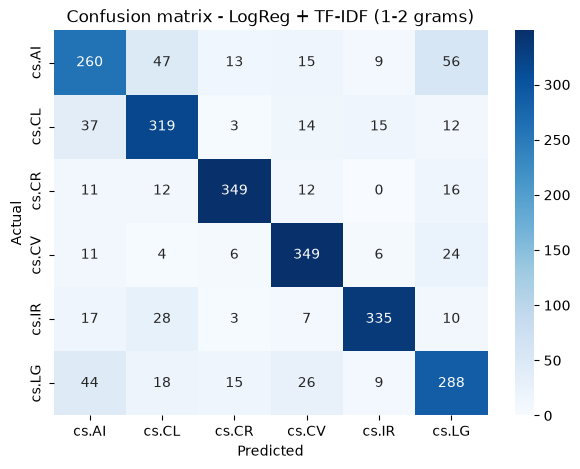

Saved artifacts\classifier.pkl -> NB06 uses classify.predict()


In [8]:
lr_cm = plot_confusion_matrix(y_test, lr_test_pred, "LogReg + TF-IDF (1-2 grams)")

path = clf.save_classifier(lr_pipeline)
print("Saved", path.relative_to(ARTIFACTS_DIR.parent), "-> NB06 uses classify.predict()")

## Transformer or LLM classifier

Four advanced classifiers, each compared with the classical baseline above:
1. **Zero-shot NLI** (Week 7): no training; the model scores "This text is about {category name}" for each category.
2. **LSTM** (Week 6, lite): the simplified LSTM from the practical with a Hugging Face tokenizer, 2 epochs.
3. **Fine-tuned DistilBERT** (Week 9, lite): Hugging Face `Trainer`, 1 epoch on 3,000 training papers. Without a GPU it falls back to frozen DistilBERT features + Logistic Regression.
4. **Few-shot LLM** (Week 9 prompting) through the team's `llm.generate`.

### Zero-shot NLI classifier (W7)

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Week 7 zero-shot classification uses an NLI model to score "This paper is about {category}" with no training at all, so it is the cheapest possible classifier to deploy. It is expected to lose to supervised TF-IDF models because arXiv category names are vague (cs.AI vs cs.LG), which is exactly the point the comparison makes.


In [9]:
import json
from transformers import pipeline

zero_shot = pipeline("zero-shot-classification", model=ZERO_SHOT_MODEL, device=0 if HAS_GPU else -1)
label_to_code = {name: code for code, name in clf.CATEGORY_NAMES.items()}
candidate_labels = list(label_to_code)

zs_df = test_df.sample(n=ZERO_SHOT_N, random_state=SEED).reset_index(drop=True)
ZS_CACHE = ARTIFACTS_DIR / "03_zero_shot_pred.json"      # cached: the 500 CPU inferences take a long time
if ZS_CACHE.exists():
    zs_pred = json.loads(ZS_CACHE.read_text())
    print("Loaded cached zero-shot predictions:", len(zs_pred))
else:
    zs_pred = []
    start = time.time()
    for i, text in enumerate(zs_df["text"]):
        # "This paper is about {}." fits research abstracts better than the default "This example is {}."
        result = zero_shot(clf.shorten(text, 1500), candidate_labels,
                           hypothesis_template="This paper is about {}.", multi_label=False)
        zs_pred.append(label_to_code[result["labels"][0]])     # top-scoring category name -> code
        if (i + 1) % 100 == 0:
            print(f"{i + 1}/{ZERO_SHOT_N} done ({time.time() - start:.0f} s)")
    ZS_CACHE.write_text(json.dumps(zs_pred))

zs_row = evaluate(zs_df["primary_category"], zs_pred, "Zero-shot NLI (DeBERTa-v3)", f"{ZERO_SHOT_N}-paper subset")
results["models"].append(zs_row)
zs_row

c:\Users\USER\Master of IT\2026 S2\COMP8460 - Artificial Intelligence for Natural Language Processing Applications\venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

100/500 done (12 s)
200/500 done (23 s)
300/500 done (32 s)
400/500 done (42 s)
500/500 done (52 s)


{'model': 'Zero-shot NLI (DeBERTa-v3)',
 'test_papers': 500,
 'accuracy': 0.366,
 'macro_precision': 0.601,
 'macro_recall': 0.372,
 'macro_f1': 0.356,
 'note': '500-paper subset'}

### LSTM (W6, lite)

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** The Week 6 simplified LSTM is included as the neural sequence baseline between bag-of-words and transformers. With a Hugging Face tokenizer and two epochs on 9.6k abstracts it is under-trained by design ("lite"); the mean-pooling over non-PAD tokens is required because abstracts are padded to 256 tokens and the final hidden state otherwise forgets the text.


In [10]:
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer

device = torch.device("cuda" if HAS_GPU else "cpu")
tokenizer = AutoTokenizer.from_pretrained(DISTILBERT)
label2id = {code: i for i, code in enumerate(CATEGORIES)}
id2label = {i: code for code, i in label2id.items()}


def encode(texts, labels, max_length=256):
    """Tokenise with the Hugging Face tokenizer (Week 6, 2.2) and pack ids + labels into a TensorDataset."""
    tokens = tokenizer(list(texts), padding="max_length", truncation=True,
                       max_length=max_length, return_tensors="pt")
    label_ids = torch.tensor([label2id[label] for label in labels])
    return TensorDataset(tokens["input_ids"], label_ids)


lstm_train = encode(train_df["text"], y_train)
lstm_test = encode(test_df["text"], y_test)
print("train:", len(lstm_train), "test:", len(lstm_test))

train: 9600 test: 2400


In [11]:
class LSTMClassifier(nn.Module):
    """Week 6 simplified LSTM, changed from 1 sigmoid output to 6 class scores."""

    def __init__(self, vocab_size, num_classes, embedding_dim=128, hidden_dim=64, num_layers=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers, batch_first=True, dropout=0.2)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids):
        embedded = self.embedding(input_ids)
        lstm_out, _ = self.lstm(embedded)
        # Mean-pool over real tokens only. Abstracts are right-padded to 256, so the final hidden
        # state (used in the practical) has read 100+ PAD tokens and forgets the text -> near-random accuracy.
        mask = (input_ids != tokenizer.pad_token_id).unsqueeze(-1).float()
        pooled = (lstm_out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.classifier(self.dropout(pooled))   # raw scores; CrossEntropyLoss applies softmax


lstm = LSTMClassifier(vocab_size=len(tokenizer), num_classes=len(CATEGORIES)).to(device)
optimizer = optim.Adam(lstm.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
train_loader = DataLoader(lstm_train, batch_size=32, shuffle=True)
test_loader = DataLoader(lstm_test, batch_size=64)

for epoch in range(2):
    lstm.train()
    total_loss, correct, seen = 0.0, 0, 0
    for input_ids, labels in train_loader:
        input_ids, labels = input_ids.to(device), labels.to(device)
        optimizer.zero_grad()
        scores = lstm(input_ids)
        loss = criterion(scores, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (scores.argmax(dim=1) == labels).sum().item()
        seen += labels.size(0)
    print(f"Epoch {epoch + 1}/2: loss = {total_loss / len(train_loader):.4f}, train accuracy = {correct / seen:.3f}")

lstm.eval()
lstm_pred = []
with torch.no_grad():
    for input_ids, labels in test_loader:
        scores = lstm(input_ids.to(device))
        lstm_pred.extend(id2label[i] for i in scores.argmax(dim=1).cpu().tolist())

lstm_row = evaluate(y_test, lstm_pred, "LSTM (2 epochs)")
results["models"].append(lstm_row)
lstm_row

Epoch 1/2: loss = 1.4650, train accuracy = 0.394
Epoch 2/2: loss = 0.9099, train accuracy = 0.676


{'model': 'LSTM (2 epochs)',
 'test_papers': 2400,
 'accuracy': 0.677,
 'macro_precision': 0.687,
 'macro_recall': 0.677,
 'macro_f1': 0.678}

### Fine-tuned DistilBERT (W9, lite)

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Week 9 fine-tuning adapts a pretrained encoder to our six labels: one epoch on 3,000 papers (GPU) is enough to show whether contextual representations beat TF-IDF here. The frozen-encoder + LogReg fallback is the Week 9 "feature extraction" variant, so both fine-tuning types from the lecture are covered and compared.


In [12]:
from datasets import Dataset
from transformers import AutoModelForSequenceClassification, AutoModel, Trainer, TrainingArguments

ft_train_df = train_df.groupby("primary_category", group_keys=False).sample(
    n=FINETUNE_TRAIN_N // len(CATEGORIES), random_state=SEED)          # 500 per category = 3,000
distilbert_probs = None

if HAS_GPU:
    def tokenize_function(examples):
        return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=256)

    def to_dataset(frame):
        data = Dataset.from_pandas(pd.DataFrame({
            "text": frame["text"].tolist(),
            "labels": [label2id[c] for c in frame["primary_category"]]}))
        return data.map(tokenize_function, batched=True)

    tokenized_train = to_dataset(ft_train_df)
    tokenized_test = to_dataset(test_df)

    model = AutoModelForSequenceClassification.from_pretrained(
        DISTILBERT, num_labels=len(CATEGORIES), id2label=id2label, label2id=label2id)
    training_args = TrainingArguments(
        output_dir=str(ARTIFACTS_DIR / "models" / "distilbert_runs"),
        num_train_epochs=1, per_device_train_batch_size=16, per_device_eval_batch_size=64,
        learning_rate=5e-5, weight_decay=0.01, logging_steps=50,
        eval_strategy="no", save_strategy="no", report_to="none", seed=SEED)
    trainer = Trainer(model=model, args=training_args, train_dataset=tokenized_train)

    start = time.time()
    trainer.train()
    print(f"Fine-tuning took {time.time() - start:.0f} s")

    logits = trainer.predict(tokenized_test).predictions
    distilbert_probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
    distilbert_pred = [id2label[i] for i in logits.argmax(axis=1)]
    model.save_pretrained(ARTIFACTS_DIR / "models" / "distilbert")
    tokenizer.save_pretrained(ARTIFACTS_DIR / "models" / "distilbert")
    distilbert_row = evaluate(y_test, distilbert_pred, f"DistilBERT fine-tuned (1 epoch, {len(ft_train_df)} train)")
else:
    # No GPU: use DistilBERT as a frozen feature extractor ([CLS] vector) + Logistic Regression
    encoder = AutoModel.from_pretrained(DISTILBERT).to(device).eval()

    def cls_vectors(texts, batch_size=32):
        vectors = []
        texts = list(texts)
        with torch.no_grad():
            for i in range(0, len(texts), batch_size):
                batch = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                                  max_length=256, return_tensors="pt").to(device)
                vectors.append(encoder(**batch).last_hidden_state[:, 0].cpu().numpy())
        return np.vstack(vectors)

    frozen_lr = LogisticRegression(max_iter=2000, random_state=SEED).fit(
        cls_vectors(ft_train_df["text"]), ft_train_df["primary_category"])
    distilbert_pred = frozen_lr.predict(cls_vectors(test_df["text"]))
    distilbert_row = evaluate(y_test, distilbert_pred, "Frozen DistilBERT + LogReg (no GPU fallback)")

results["models"].append(distilbert_row)
distilbert_row

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2400 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'loss': '1.47', 'grad_norm': '4.769', 'learning_rate': '3.697e-05', 'epoch': '0.266'}
{'loss': '0.9347', 'grad_norm': '4.997', 'learning_rate': '2.367e-05', 'epoch': '0.5319'}
{'loss': '0.7525', 'grad_norm': '7.436', 'learning_rate': '1.037e-05', 'epoch': '0.7979'}
{'train_runtime': '35.27', 'train_samples_per_second': '85.06', 'train_steps_per_second': '5.331', 'train_loss': '0.9884', 'epoch': '1'}
Fine-tuning took 35 s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'model': 'DistilBERT fine-tuned (1 epoch, 3000 train)',
 'test_papers': 2400,
 'accuracy': 0.759,
 'macro_precision': 0.755,
 'macro_recall': 0.759,
 'macro_f1': 0.755}

### Few-shot LLM classifier (W9 prompting)

The prompt lists the six arXiv category names, then gives one worked example per category taken from the **training** set, then the test paper. The reply is parsed for a category code; an unparseable reply counts as wrong.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** A few-shot prompt (Week 9) with one training example per category tests whether a general instruction-tuned LLM can classify research domains from the category names alone. It needs no training but is slow and non-deterministic in format, so replies are parsed for a category code and unparseable answers are counted as errors rather than dropped.


In [13]:
import llm
print("LLM backend:", llm.describe())

examples = []
for category in CATEGORIES:
    example = train_df[y_train == category].sample(n=1, random_state=SEED).iloc[0]
    examples.append((example["text"], category))

llm_df = test_df.sample(n=LLM_N, random_state=SEED).reset_index(drop=True)
print(clf.build_few_shot_prompt(llm_df.loc[0, "text"], examples)[:1500], "...")

LLM backend: {'backend': 'hf', 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
Categories:
- cs.AI: Artificial Intelligence
- cs.CL: Computation and Language (natural language processing)
- cs.CR: Cryptography and Security
- cs.CV: Computer Vision and Pattern Recognition
- cs.IR: Information Retrieval
- cs.LG: Machine Learning

Paper: The Digital Apprentice: A Framework for Human-Directed Agentic AI Development. Agentic AI deployments face a recurring design tension: heavy human oversight limits scale, while broad autonomy outruns accountability. Neither posture provides the governance infrastructure required for responsible delegation. We present the Digital Apprentice, a framework for scalable, safe AI agency in which ...
Category: cs.AI

Paper: EvoCodeBench: An Evolving Code Generation Benchmark with Domain-Specific Evaluations. How to evaluate Large Language Models (LLMs) in code generation remains an open question. Existing benchmarks have two limitations - data leakage and lack of domain-

In [14]:
llm_pred = []
start = time.time()
for i, text in enumerate(llm_df["text"]):
    llm_pred.append(clf.llm_classify(text, examples))
    if (i + 1) % 50 == 0:
        print(f"{i + 1}/{LLM_N} done ({time.time() - start:.0f} s)")

unparsed = sum(1 for p in llm_pred if p is None)
llm_pred_filled = [p if p is not None else "unparsed" for p in llm_pred]
llm_row = evaluate(llm_df["primary_category"], llm_pred_filled, "Few-shot LLM", f"{LLM_N}-paper subset, {unparsed} unparsed")
results["models"].append(llm_row)
llm_row

50/200 done (0 s)
100/200 done (0 s)
150/200 done (0 s)
200/200 done (0 s)


{'model': 'Few-shot LLM',
 'test_papers': 200,
 'accuracy': 0.415,
 'macro_precision': 0.574,
 'macro_recall': 0.412,
 'macro_f1': 0.388,
 'note': '200-paper subset, 0 unparsed'}

## Ensemble (optional)

Soft voting: average the class probabilities of two models and take the most likely class. LogReg + Naive Bayes always runs (both are cheap); LogReg + fine-tuned DistilBERT runs when the GPU fine-tune above produced probabilities.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** Soft voting (Week 12 ensemble methods) averages class probabilities of two different model families, which helps when their errors are uncorrelated. LogReg + NB is cheap and always runs; LogReg + DistilBERT is the stronger pair when the GPU run is available.


In [15]:
lr_probs = lr_pipeline.predict_proba(test_df["text"])           # columns follow lr_pipeline.classes_
nb_probs = nb_tfidf.predict_proba(X_test_tfidf)
assert list(lr_pipeline.classes_) == list(nb_tfidf.classes_) == CATEGORIES

ensemble_rows = []
avg = (lr_probs + nb_probs) / 2
ensemble_rows.append(evaluate(y_test, [CATEGORIES[i] for i in avg.argmax(axis=1)], "Ensemble: LogReg + NB"))

if distilbert_probs is not None:
    avg = (lr_probs + distilbert_probs) / 2
    ensemble_rows.append(evaluate(y_test, [CATEGORIES[i] for i in avg.argmax(axis=1)], "Ensemble: LogReg + DistilBERT"))

results["models"].extend(ensemble_rows)
pd.DataFrame(ensemble_rows)

,model,test_papers,accuracy,macro_precision,macro_recall,macro_f1
0,Ensemble: LogReg + NB,2400,0.792,0.791,0.792,0.791
1,Ensemble: LogReg + DistilBERT,2400,0.778,0.775,0.778,0.775


## Comparison table and error analysis

The zero-shot and LLM rows use subsets, so the LogReg baseline is also scored on exactly the same subsets for a fair comparison.

<!-- draft written with an AI assistant from the notebook's own code and numbers; owner to review and reword before submission -->
> **Justification.** All models are compared on the same held-out split, and the zero-shot/LLM rows are paired with LogReg on identical subsets so differences are not an artefact of subset choice. The confusion pairs and the cross-listed vs single-category accuracy show how much of the remaining error is label ambiguity rather than model weakness.


In [16]:
lr_by_id = dict(zip(test_df["id"], lr_test_pred))
fair_rows = [
    evaluate(zs_df["primary_category"], [lr_by_id[i] for i in zs_df["id"]], f"LogReg (same {ZERO_SHOT_N} as zero-shot)", f"{ZERO_SHOT_N}-paper subset"),
    evaluate(llm_df["primary_category"], [lr_by_id[i] for i in llm_df["id"]], f"LogReg (same {LLM_N} as LLM)", f"{LLM_N}-paper subset"),
]
results["models"].extend(fair_rows)

comparison = pd.DataFrame(results["models"]).set_index("model")
comparison.sort_values("macro_f1", ascending=False)

,test_papers,accuracy,macro_precision,macro_recall,macro_f1,note
model,,,,,,
LogReg (same 200 as LLM),200,0.825,0.828,0.826,0.827,200-paper subset
LogReg (same 500 as zero-shot),500,0.814,0.815,0.812,0.813,500-paper subset
LogReg + TF-IDF (1-2 grams),2400,0.792,0.793,0.792,0.792,NaN
Ensemble: LogReg + NB,2400,0.792,0.791,0.792,0.791,NaN
LogReg + TF-IDF,2400,0.787,0.789,0.787,0.788,NaN
Ensemble: LogReg + DistilBERT,2400,0.778,0.775,0.778,0.775,NaN
Naive Bayes + BoW,2400,0.773,0.774,0.773,0.773,NaN
Naive Bayes + TF-IDF,2400,0.770,0.769,0.770,0.769,NaN
"DistilBERT fine-tuned (1 epoch, 3000 train)",2400,0.759,0.755,0.759,0.755,NaN


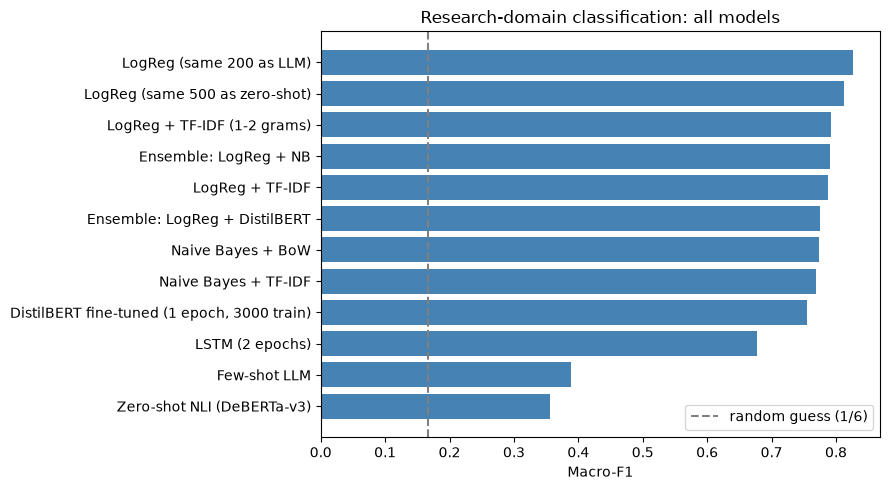

In [17]:
plot_table = comparison.sort_values("macro_f1")
plt.figure(figsize=(9, 5))
plt.barh(plot_table.index, plot_table["macro_f1"], color="steelblue")
plt.axvline(1 / len(CATEGORIES), color="grey", linestyle="--", label="random guess (1/6)")
plt.xlabel("Macro-F1")
plt.title("Research-domain classification: all models")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Which domains get confused with each other? (off-diagonal cells of the LogReg confusion matrix)
pairs = []
for i, actual in enumerate(CATEGORIES):
    for j, predicted in enumerate(CATEGORIES):
        if i != j:
            pairs.append((actual, predicted, int(lr_cm[i, j])))
confused = pd.DataFrame(sorted(pairs, key=lambda p: -p[2])[:6], columns=["actual", "predicted", "papers"])
results["most_confused_pairs"] = confused.to_dict(orient="records")
confused

,actual,predicted,papers
0,cs.AI,cs.LG,56
1,cs.AI,cs.CL,47
2,cs.LG,cs.AI,44
3,cs.CL,cs.AI,37
4,cs.IR,cs.CL,28
5,cs.LG,cs.CV,26


In [19]:
# Cross-listing: are errors concentrated in papers listed under more than one category?
errors = test_df.assign(predicted=lr_test_pred)
errors["correct"] = errors["predicted"] == errors["primary_category"]
errors["cross_listed"] = errors["all_categories"].str.len() > 1
# "lenient" = the prediction is one of the paper's categories, even if not the primary one
errors["lenient_correct"] = [p in cats for p, cats in zip(errors["predicted"], errors["all_categories"])]

by_listing = errors.groupby("cross_listed")["correct"].agg(["count", "mean"]).round(3)
by_listing.index = ["single category", "cross-listed"]
results["accuracy_by_listing"] = by_listing["mean"].to_dict()
results["lenient_accuracy_logreg"] = round(float(errors["lenient_correct"].mean()), 3)
print("Strict accuracy :", round(float(errors["correct"].mean()), 3))
print("Lenient accuracy:", results["lenient_accuracy_logreg"], "(prediction is any of the paper's listed categories)")
by_listing

Strict accuracy : 0.792
Lenient accuracy: 0.875 (prediction is any of the paper's listed categories)


,count,mean
single category,1068,0.828
cross-listed,1332,0.763


In [20]:
# Three misclassified papers, to read by hand
for _, row in errors[~errors["correct"]].sample(n=3, random_state=SEED).iterrows():
    print(f"actual {row['primary_category']} | predicted {row['predicted']} | all categories {row['all_categories']}")
    print("  ", row["title"], "\n")

actual cs.AI | predicted cs.CL | all categories ['cs.AI', 'cs.CL']
   Systematic Generalization on gSCAN with Language Conditioned Embedding 

actual cs.CL | predicted cs.LG | all categories ['cs.CL', 'cs.LG']
   Interpretable phenotyping of Heart Failure patients with Dutch discharge letters 

actual cs.AI | predicted cs.CL | all categories ['cs.AI']
   Evaluating the Hidden Costs of Personalization in Large Language Models 



## Findings and limitations

> **Owner, 2-4 lines each, from the numbers above:**
> - Best model and how far the transformer / LLM models are from the TF-IDF baseline (and on which subset).
> - What the confusion pairs and the cross-listed vs single-category accuracy say about the labels themselves.
> - Limitations: subsets for zero-shot / LLM, 1 epoch / 3k papers for DistilBERT, 2 epochs for the LSTM, one label per paper although many papers have several.

In [21]:
path = save_results("03", results)
print("Saved", path.relative_to(ARTIFACTS_DIR.parent))
comparison

Saved artifacts\03_results.json


,test_papers,accuracy,macro_precision,macro_recall,macro_f1,note
model,,,,,,
Naive Bayes + BoW,2400,0.773,0.774,0.773,0.773,NaN
Naive Bayes + TF-IDF,2400,0.770,0.769,0.770,0.769,NaN
LogReg + TF-IDF,2400,0.787,0.789,0.787,0.788,NaN
LogReg + TF-IDF (1-2 grams),2400,0.792,0.793,0.792,0.792,NaN
Zero-shot NLI (DeBERTa-v3),500,0.366,0.601,0.372,0.356,500-paper subset
LSTM (2 epochs),2400,0.677,0.687,0.677,0.678,NaN
"DistilBERT fine-tuned (1 epoch, 3000 train)",2400,0.759,0.755,0.759,0.755,NaN
Few-shot LLM,200,0.415,0.574,0.412,0.388,"200-paper subset, 0 unparsed"
Ensemble: LogReg + NB,2400,0.792,0.791,0.792,0.791,NaN
